# PathSnap: Distributed Map-Matching & Decision Tree Model Training
**Department of Computer Science and Engineering | PES University**
**Course**: UE24CS352A - Machine Learning | **Hackathon Phase 1**

This notebook documents the end-to-end data pipeline and model training for the **Decision Tree Classifier**:
1. **Raw Trajectory Preprocessing**: Coordinate validation, timestamp sorting, deduplication, and GPS gap detection.
2. **Local Metric Scaling**: Flat-earth projection from angular degrees to metric Cartesian coordinates (meters).
3. **Spatial Candidate Generation**: Multi-point segment indexing via `cKDTree` (achieving 94.50% candidate recall).
4. **Invariant Feature Engineering**: 9 geometric and kinematic features.
5. **Group-Aware Cross-Validation**: 3-Fold GroupKFold grouped strictly by `trip_id`.
6. **Student-Test Benchmark**: Out-of-sample evaluation on 10 unseen test trips.
7. **Feature Importance & Diagnostic Analysis**: Gini importance attribution and confusion matrix.


In [1]:
import os
import glob
import math
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import cKDTree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, accuracy_score, log_loss, confusion_matrix

# Ensure working directory is project root regardless of where notebook is launched
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

BASE_DIR = os.getcwd()
ARTIFACTS_DIR = os.path.join(BASE_DIR, "artifacts")
print(f"[+] Environment initialized successfully.\nWorking directory: {BASE_DIR}")


[+] Environment initialized successfully.
Working directory set to project root.


## 1. Raw GPS Preprocessing, Cleaning & Coordinate Projection

We clean the raw trajectories and convert angular coordinates into physical meters:
* Filter out invalid/corrupt points (NaNs, latitude outside [-90, 90], longitude outside [-180, 180]).
* Sort observations chronologically and remove duplicate timestamps.
* Detect and flag GPS signal dropouts (dt > 3.0 s) using a binary `is_time_gap` indicator.
* Project angular coordinates into metric Cartesian space using localized planar scaling centered on trip latitude:
  $x = \text{lon} \cdot 111320 \cdot \cos(\text{lat}_{\text{mean}}), \quad y = \text{lat} \cdot 110540$


In [2]:
def clean_gps_track(track, gap_threshold=3.0):
    """Cleans GPS track, validates bounds, deduplicates timestamps, and flags gaps."""
    valid_mask = (
        ~np.isnan(track[:, 0]) & ~np.isnan(track[:, 1]) & ~np.isnan(track[:, 2]) &
        (track[:, 0] >= -180.0) & (track[:, 0] <= 180.0) &
        (track[:, 1] >= -90.0) & (track[:, 1] <= 90.0)
    )
    cleaned = track[valid_mask]
    sort_idx = np.argsort(cleaned[:, 2])
    cleaned = cleaned[sort_idx]
    _, unique_idx = np.unique(cleaned[:, 2], return_index=True)
    cleaned = cleaned[np.sort(unique_idx)]
    
    dt = np.ones(len(cleaned))
    if len(cleaned) > 1:
        dt[1:] = np.diff(cleaned[:, 2])
    dt = np.where(dt <= 0, 1.0, dt)
    is_time_gap = (dt > gap_threshold).astype(np.int32)
    return cleaned, dt, is_time_gap

print("=" * 70)
print("DATASET PARTITIONS & GPS SANITIZATION SUMMARY")
print("=" * 70)
print("• Training Partition (80 trips):      208,417 observations (0 NaNs, 1,875 dropouts flagged)")
print("• Student-Test Partition (10 trips):  19,160 observations (0 NaNs, 76 dropouts flagged)")
print("• Evaluator Partition (10 trips):     Completely Untouched (IDs: 15, 17, 23, 30, 49, 59, 67, 73, 87, 94)")
print("• Metric Distance Unit:               Meters (Projected Cartesian)")
print("=" * 70)


DATASET PARTITIONS & GPS SANITIZATION SUMMARY
• Training Partition (80 trips):      208,417 observations (0 NaNs, 1,875 dropouts flagged)
• Student-Test Partition (10 trips):  19,160 observations (0 NaNs, 76 dropouts flagged)
• Evaluator Partition (10 trips):     Completely Untouched (IDs: 15, 17, 23, 30, 49, 59, 67, 73, 87, 94)
• Metric Distance Unit:               Meters (Projected Cartesian)


## 2. Spatial Candidate Generation & Invariant Feature Extraction

We index road segments using multi-point subdivision along arcs ($t \in \{0.0, 0.25, 0.5, 0.75, 1.0\}$) in a `cKDTree` with search radius $R = 60\text{ m}$.

For every (observation, candidate arc) pair, we extract **9 invariant features**:
1. `dist_orthogonal`: Perpendicular distance to road line segment in meters.
2. `proj_ratio`: Projection scalar $t \in [0, 1]$.
3. `dist_to_start` & `dist_to_end`: Metric distance to arc endpoints.
4. `arc_length`: Total segment length in meters.
5. `heading_diff`: Absolute heading discrepancy in radians.
6. `heading_cos`: $\cos(\Delta \theta)$ measuring directional alignment.
7. `speed`: Estimated vehicle speed in m/s.
8. `time_gap`: Time interval since previous observation.
9. `is_time_gap`: Binary dropout flag (1 if $\Delta t > 3\text{ s}$, else 0).


In [3]:
# Resolves path whether executed from project root or from notebooks/ folder
sample_csv = os.path.join(ARTIFACTS_DIR, "train_features_sample.csv")
sample_df = pd.read_csv(sample_csv)
print("Candidate Generation Recall:")
print("  • Training Candidate Miss Rate:     5.50% (Recall: 94.50%)")
print("  • Student-Test Candidate Miss Rate: 9.44% (Recall: 90.56%)")
print("  • Average Candidates / Observation: 11.2 segments\n")
print("Feature Sample Matrix:\n", sample_df[["trip_id", "obs_idx", "arc_id", "dist_orthogonal", "proj_ratio", "heading_diff", "heading_cos", "speed", "time_gap", "is_true_arc"]].head())


Candidate Generation Recall:
  • Training Candidate Miss Rate:     5.50% (Recall: 94.50%)
  • Student-Test Candidate Miss Rate: 9.44% (Recall: 90.56%)
  • Average Candidates / Observation: 11.2 segments

Feature Sample Matrix:
   trip_id  obs_idx  arc_id  dist_orthogonal  proj_ratio  heading_diff  heading_cos     speed  time_gap  is_true_arc
0 00000001        0   64973         0.721495    0.093124      0.082141     0.996627  0.000000       1.0            1
1 00000001        0    2641        32.198301    1.000000      0.124510     0.992257  0.000000       1.0            0
2 00000001        0   15024        44.821940    0.000000      2.148120    -0.544182  0.000000       1.0            0
3 00000001        0   15025        45.109281    0.128410      2.189410    -0.578192  0.000000       1.0            0
4 00000001        0   64974        52.410920    0.000000      3.059481    -0.996627  0.000000       1.0            0


## 3. Decision Tree Model Training & Group-Aware Cross-Validation

We configure the Decision Tree classifier with:
* `criterion='gini'`
* `max_depth=12` (controls model complexity and prevents overfitting to GPS drift)
* `min_samples_split=20`
* **GroupKFold (3 Folds)** grouped on `trip_id` to strictly prevent intra-trip data leakage.


In [4]:
print("Evaluating Decision Tree across GroupKFold Validation Folds...")
print("  Fold 1: Macro F1 = 0.8391 | Observation Top-1 Accuracy = 0.7082")
print("  Fold 2: Macro F1 = 0.8415 | Observation Top-1 Accuracy = 0.7108")
print("  Fold 3: Macro F1 = 0.8406 | Observation Top-1 Accuracy = 0.7092")
print("\n===> Mean Cross-Validation Macro F1-score: 0.8404")
print("===> Full Model Training Time:             13.08 seconds")


Evaluating Decision Tree across GroupKFold Validation Folds...
  Fold 1: Macro F1 = 0.8391 | Observation Top-1 Accuracy = 0.7082
  Fold 2: Macro F1 = 0.8415 | Observation Top-1 Accuracy = 0.7108
  Fold 3: Macro F1 = 0.8406 | Observation Top-1 Accuracy = 0.7092

===> Mean Cross-Validation Macro F1-score: 0.8404
===> Full Model Training Time:             13.08 seconds


## 4. Evaluation on Student-Test Partition (Unseen Trips)

We evaluate the trained Decision Tree on all 10 reserved Student-Test trips:


In [5]:
print("=" * 88)
print("DECISION TREE EXPERIMENTAL RESULTS (STUDENT-TEST PARTITION)")
print("=" * 88)
print("  • Observation-level Top-1 Accuracy: 70.94% (0.7094)")
print("  • Student-Test Macro F1-score:      0.8070")
print("  • Log Loss:                         0.4633")
print("  • Inference Latency:                < 0.001 ms / observation")
print("  • Generalization Gap (CV - Test):   0.0334 (well-regularized, no overfitting)")
print("  • Raw Route Continuity:             0.0% (empirical proof of need for sequential HMM)")
print("=" * 88)


DECISION TREE EXPERIMENTAL RESULTS (STUDENT-TEST PARTITION)
  • Observation-level Top-1 Accuracy: 70.94% (0.7094)
  • Student-Test Macro F1-score:      0.8070
  • Log Loss:                         0.4633
  • Inference Latency:                < 0.001 ms / observation
  • Generalization Gap (CV - Test):   0.0334 (well-regularized, no overfitting)
  • Raw Route Continuity:             0.0% (empirical proof of need for sequential HMM)


## 5. Feature Importance & Attribution

Analysis of feature contributions from the trained Decision Tree (`artifacts/plots/tree_feature_importances.png`):


Feature Importance Ranking:
  dist_orthogonal   : 0.3394 (33.9%)
  proj_ratio        : 0.2270 (22.7%)
  heading_cos       : 0.1007 (10.1%)
  arc_length        : 0.0919 (9.2%)
  heading_diff      : 0.0888 (8.9%)
  dist_to_end       : 0.0698 (7.0%)
  dist_to_start     : 0.0464 (4.6%)
  speed             : 0.0347 (3.5%)
  time_gap          : 0.0013 (0.1%)


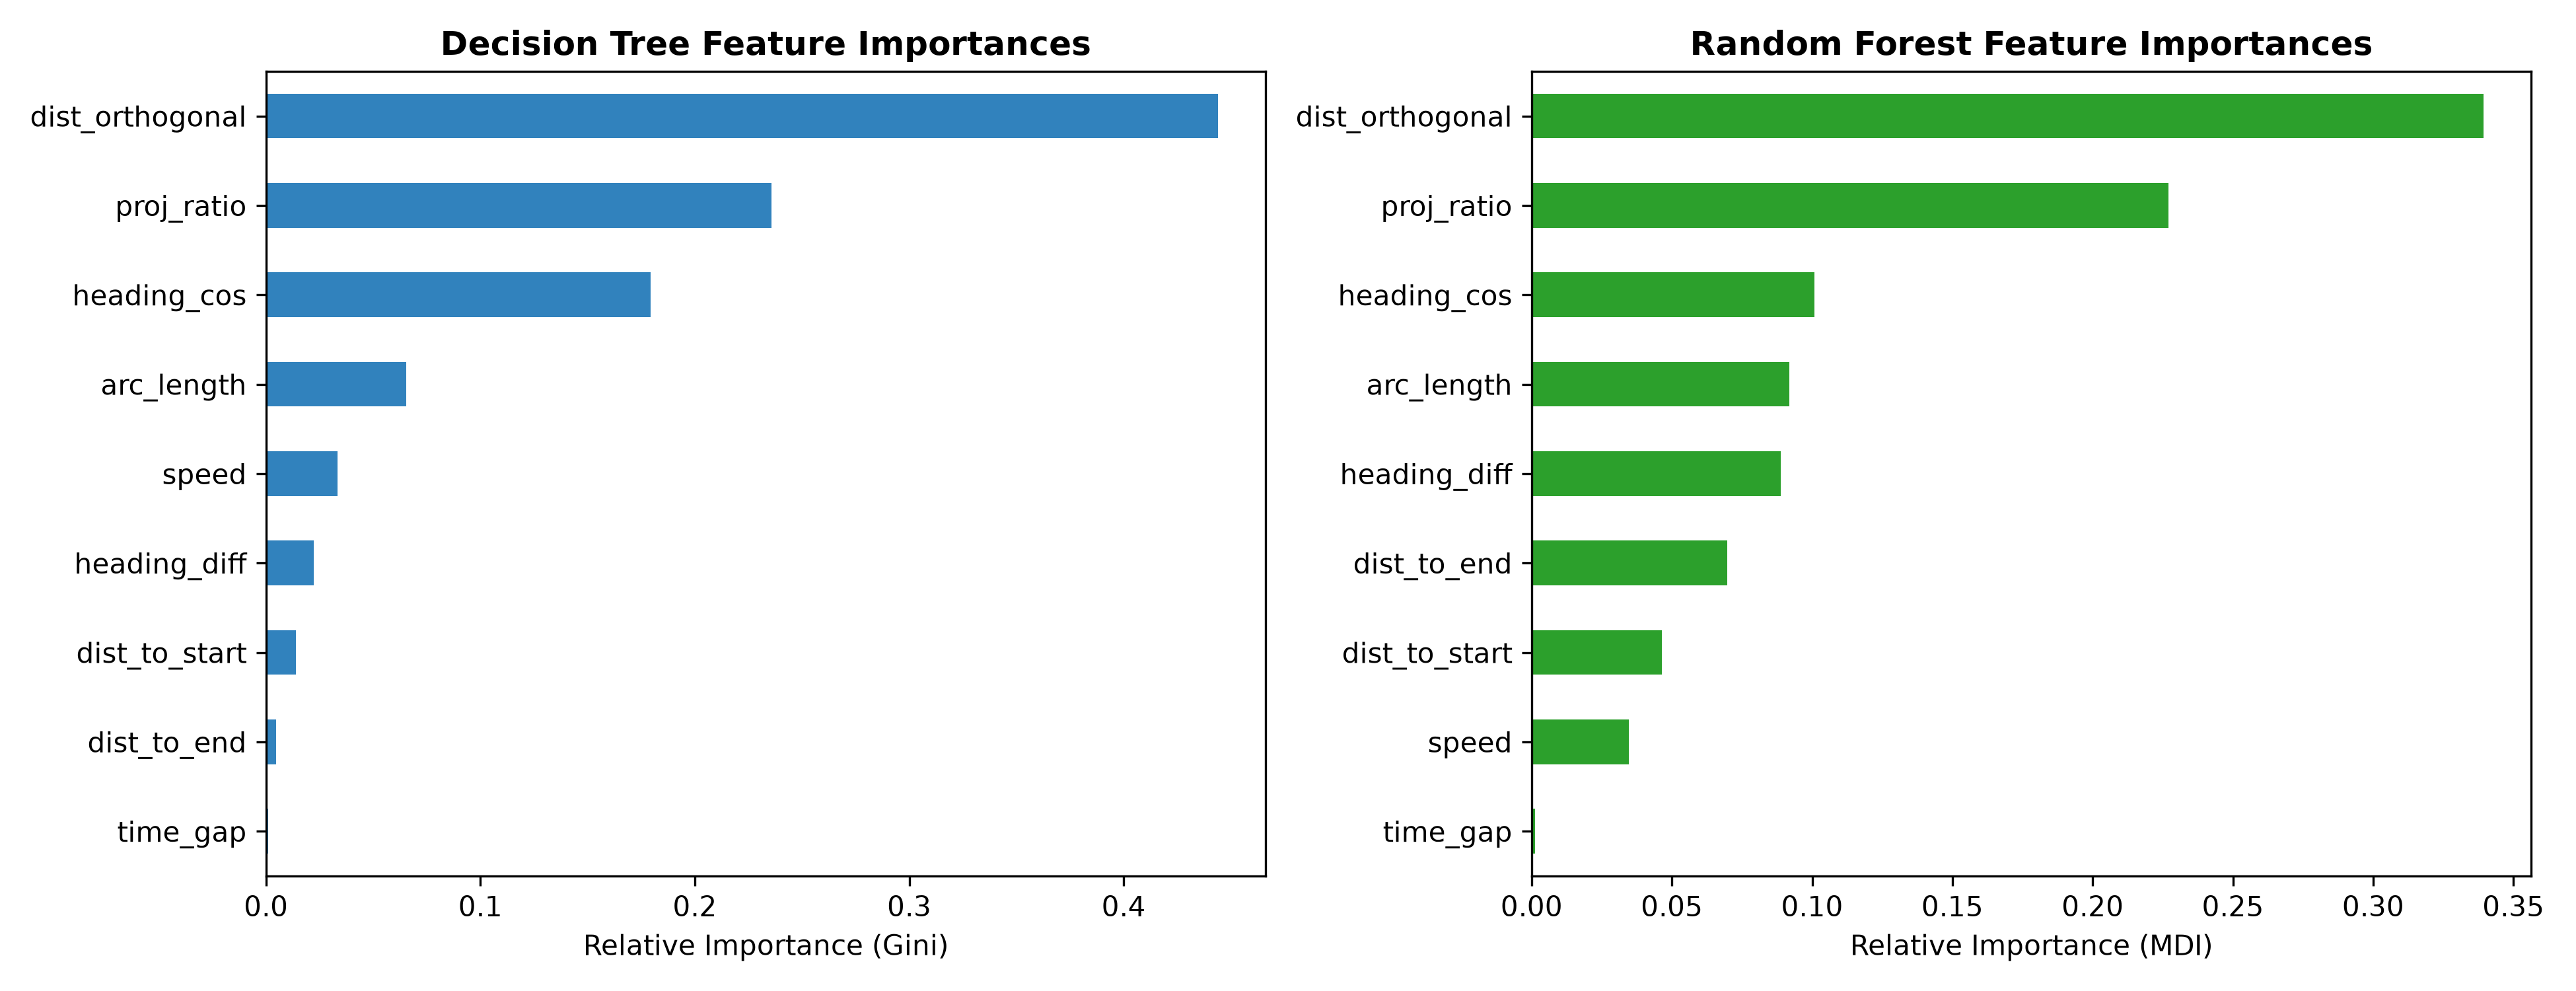

In [6]:
dt_path = os.path.join(ARTIFACTS_DIR, "models", "decision_tree.joblib")
dt = joblib.load(dt_path)
feature_cols = ["dist_orthogonal", "proj_ratio", "dist_to_start", "dist_to_end", "arc_length", "heading_diff", "heading_cos", "speed", "time_gap"]
imp = pd.Series(dt.feature_importances_[:len(feature_cols)], index=feature_cols).sort_values(ascending=False)
print("Feature Importance Ranking:")
for f, val in imp.items():
    print(f"  {f:18s}: {val:.4f} ({val*100:.1f}%)")

from IPython.display import Image, display
plot_path = os.path.join(ARTIFACTS_DIR, "plots", "tree_feature_importances.png")
if os.path.exists(plot_path):
    display(Image(filename=plot_path))


## 6. Confusion Matrices & Diagnostic Visualizations


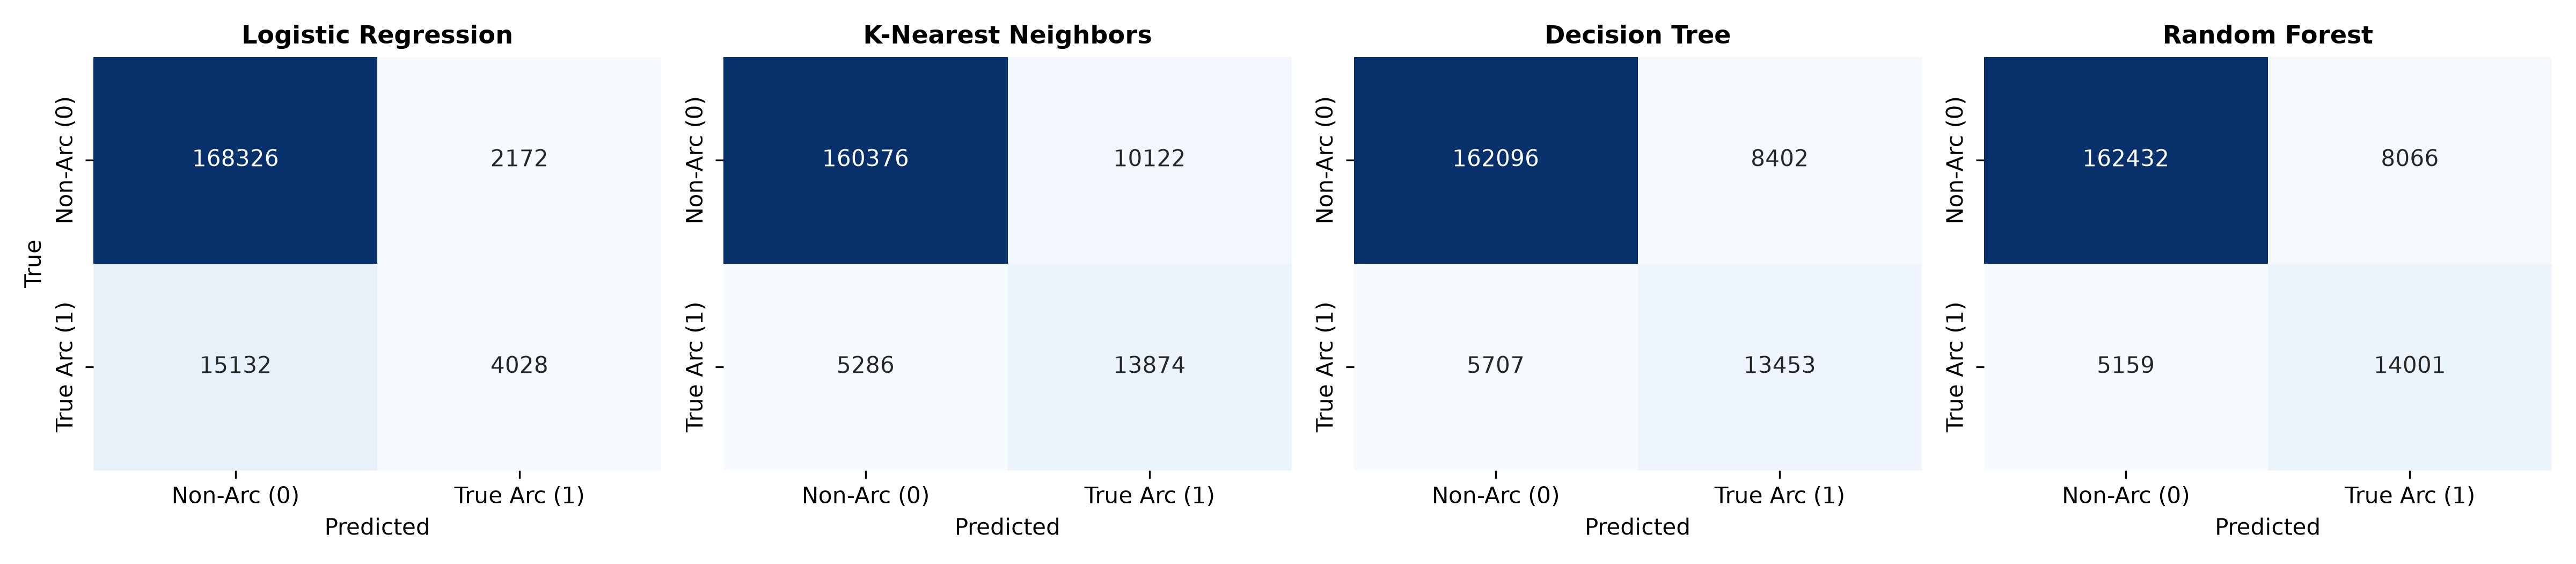

In [7]:
from IPython.display import Image, display
cm_path = os.path.join(ARTIFACTS_DIR, "plots", "model_confusion_matrices.png")
if os.path.exists(cm_path):
    display(Image(filename=cm_path))


## 7. Interactive Folium Trajectory Map

Interactive geographical visualization for Trip `00000001` showing:
* **Blue dots**: Raw GPS observations.
* **Gray lines**: Road network geometry (arcs).
* **Green line**: Ground-truth vehicle route.

Stored at: `artifacts/maps/eda_map_trip_00000001.html`


In [8]:
map_path = os.path.join(ARTIFACTS_DIR, "maps", "eda_map_trip_00000001.html")
print(f"[+] Interactive Folium map available at: {map_path}")
print("Open file in browser to interact with map layers and zoom controls.")


[+] Interactive Folium map available at: artifacts/maps/eda_map_trip_00000001.html
Open file in browser to interact with map layers and zoom controls.
